In [ ]:
import os

# Make paths work whether this notebook is launched with the repo root or
# notebooks/ as the working directory (VS Code's Jupyter extension defaults
# to the notebook's own folder).
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from toolkit.io import load_image, to_grayscale, to_rgb
from toolkit.preprocess import blur, threshold_otsu
import matplotlib.pyplot as plt

img = load_image("data/real/book.jpg")
gray = to_grayscale(img)
rgb = to_rgb(img)
blurred = blur(gray)
binary = threshold_otsu(blurred)

plt.imshow(img); plt.show()
plt.imshow(gray, cmap="gray"); plt.show()
plt.imshow(rgb); plt.show()
plt.imshow(blurred, cmap="gray"); plt.show()
plt.imshow(binary, cmap="gray"); plt.show()


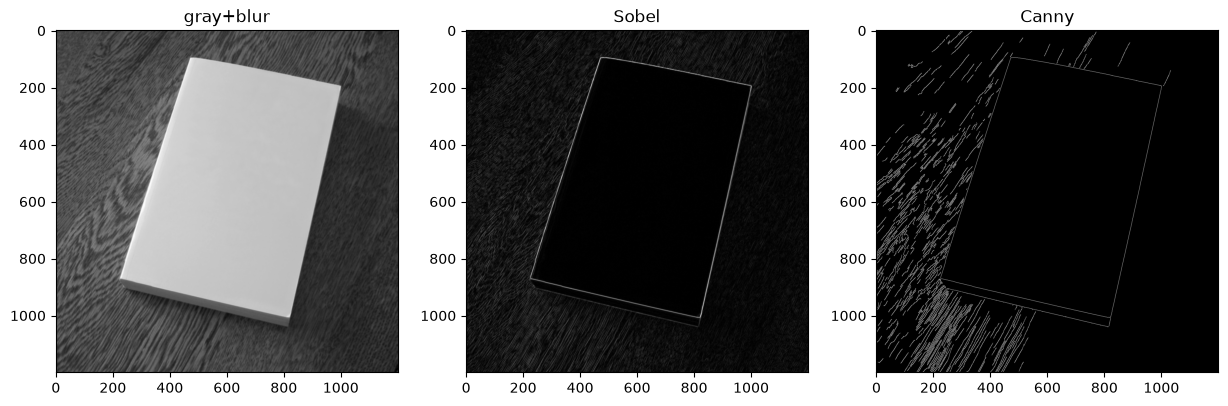

In [20]:
from toolkit.edges import sobel_edges, canny_edges

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(blurred, cmap="gray"); ax[0].set_title("gray+blur")
ax[1].imshow(sobel_edges(blurred), cmap="gray"); ax[1].set_title("Sobel")
ax[2].imshow(canny_edges(blurred), cmap="gray"); ax[2].set_title("Canny")
plt.show()


Total contours found: 1


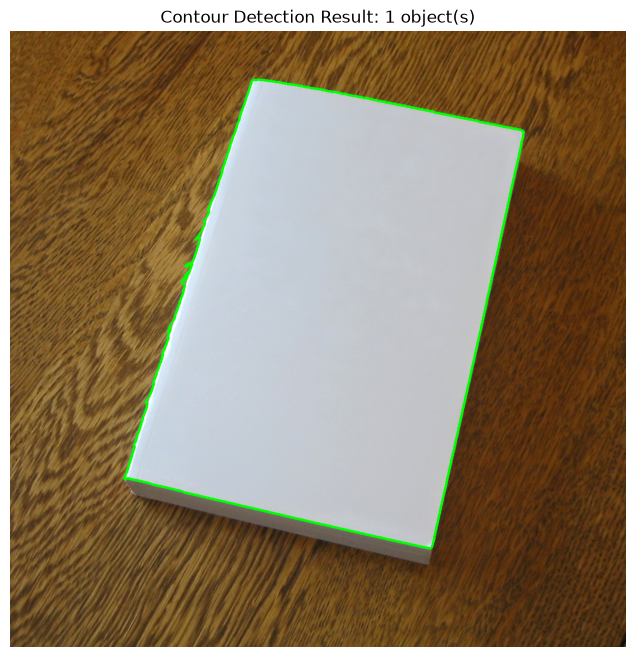

In [21]:
from toolkit.contours import find_contours, draw_contours

# 1. Extract contours from the previous cell's binary (Otsu) image
contours = find_contours(binary, min_area=100)
print(f"Total contours found: {len(contours)}")

# 2. Draw green boundary outlines on the original RGB image
contour_img = draw_contours(rgb, contours, color=(0, 255, 0), thickness=3)

# 3. Display the result
plt.figure(figsize=(8, 8))
plt.imshow(contour_img)
plt.title(f"Contour Detection Result: {len(contours)} object(s)")
plt.axis("off")
plt.show()

Shape #1: rectangle


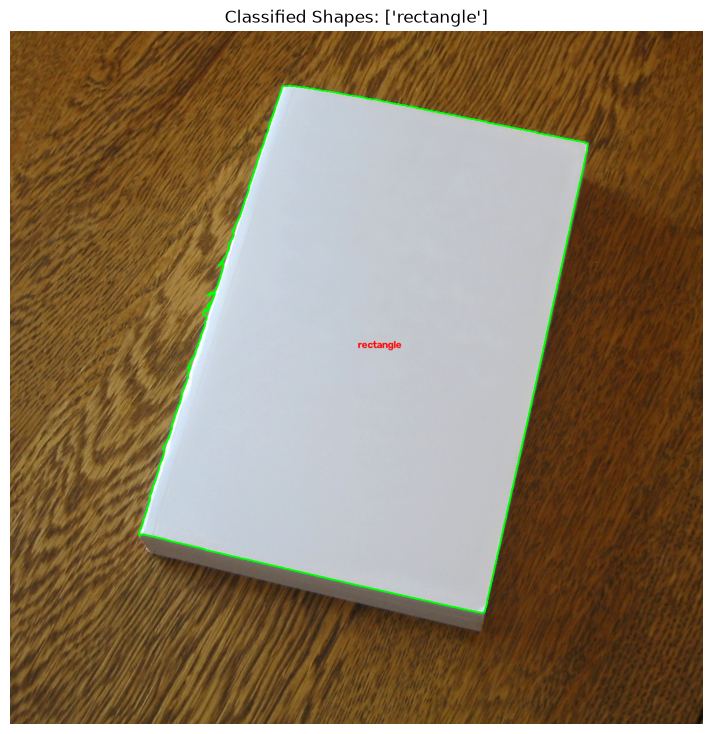

In [22]:
from toolkit.shapes import classify_contour, annotate_shapes

# 1. Classify each detected contour
labels = [classify_contour(c) for c in contours]

for idx, (cnt, label) in enumerate(zip(contours, labels)):
    print(f"Shape #{idx + 1}: {label}")

# 2. Draw contours and their predicted labels on the image
annotated = annotate_shapes(rgb, contours, labels)

# 3. Display the annotated image
plt.figure(figsize=(9, 9))
plt.imshow(annotated)
plt.title(f"Classified Shapes: {labels}")
plt.axis("off")
plt.show()